In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

df_transactions = pd.read_csv(
    PROCESSED_DIR / "cleaned_transactions.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "Invoice": "string",
        "StockCode": "string"
    },
    low_memory=False
)

print("Shape:", df_transactions.shape)
print("Unique customers:", df_transactions["Customer ID"].nunique())
print("Date range:")
print(df_transactions["InvoiceDate"].min())
print(df_transactions["InvoiceDate"].max())

Shape: (1007913, 11)
Unique customers: 5878
Date range:
2009-12-01 07:45:00
2011-12-09 12:50:00


In [25]:
from pathlib import Path

FIGURE_DIR = PROJECT_ROOT / "docs" / "segmentation" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figures folder:", FIGURE_DIR)

Figures folder: c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\docs\segmentation\figures


Create the RFM table

In [3]:
# Keep only transactions with identified customers
df_rfm_source = df_transactions[
    df_transactions["Customer ID"].notna()
].copy()

# Reference date: one day after the final transaction
reference_date = (
    df_rfm_source["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# Aggregate transaction data at customer level
rfm = df_rfm_source.groupby("Customer ID").agg(
    Recency=(
        "InvoiceDate",
        lambda dates: (reference_date - dates.max()).days
    ),
    Frequency=("Invoice", "nunique"),
    Monetary=("TransactionValue", "sum")
).reset_index()

print("RFM DATASET")
print("-" * 40)
print("Customers:", len(rfm))
print("Features:", rfm.columns.tolist())

display(rfm.head(10))

RFM DATASET
----------------------------------------
Customers: 5878
Features: ['Customer ID', 'Recency', 'Frequency', 'Monetary']


,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93
6,12352.0,36,10,2849.84
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61


In [4]:
# Keep Customer ID as an integer identifier
rfm["Customer ID"] = rfm["Customer ID"].astype("Int64")

# Statistical summary
print("RFM DESCRIPTIVE STATISTICS")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\nSKEWNESS")
print(rfm[["Recency", "Frequency", "Monetary"]].skew())

print("\nMISSING VALUES")
print(rfm.isnull().sum())

RFM DESCRIPTIVE STATISTICS


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.331916,6.289384,2955.904095
std,209.338707,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000



SKEWNESS
Recency       0.887198
Frequency    12.639951
Monetary     25.070190
dtype: float64

MISSING VALUES
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64


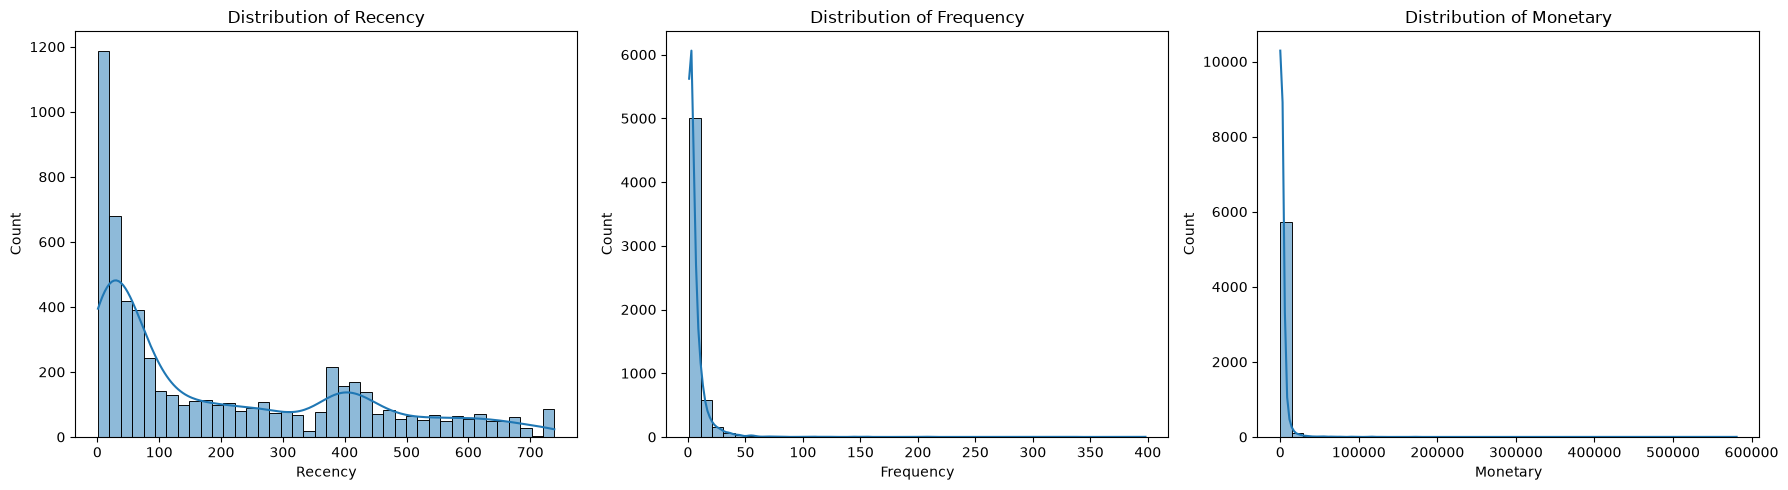

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["Recency", "Frequency", "Monetary"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, features):
    sns.histplot(
        data=rfm,
        x=feature,
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")
    plt.savefig(
    FIGURE_DIR / "rfm_distributions_before.png",
    dpi=300,
    bbox_inches="tight"
)


plt.tight_layout()
plt.show()

In [6]:
import numpy as np

# Preserve the original RFM dataset
rfm_transformed = rfm.copy()

# Apply logarithmic transformation
rfm_transformed["Frequency"] = np.log1p(
    rfm_transformed["Frequency"]
)

rfm_transformed["Monetary"] = np.log1p(
    rfm_transformed["Monetary"]
)

print("SKEWNESS AFTER TRANSFORMATION")

print(
    rfm_transformed[
        ["Recency", "Frequency", "Monetary"]
    ].skew()
)

display(rfm_transformed.head())

SKEWNESS AFTER TRANSFORMATION
Recency      0.887198
Frequency    1.001471
Monetary     0.269125
dtype: float64


,Customer ID,Recency,Frequency,Monetary
0,12346,326,2.564949,11.258774
1,12347,2,2.197225,8.501578
2,12348,75,1.791759,7.611051
3,12349,19,1.609438,8.396085
4,12350,310,0.693147,5.815324


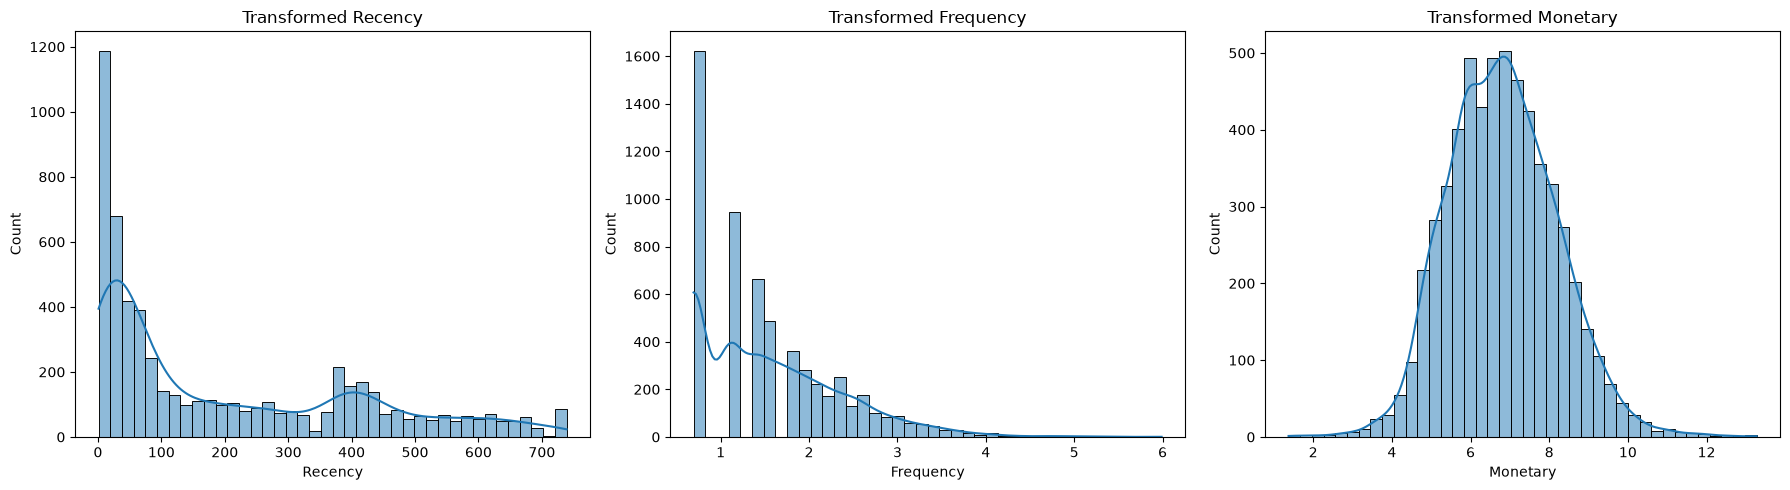

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["Recency", "Frequency", "Monetary"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, features):
    sns.histplot(
        data=rfm_transformed,
        x=feature,
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Transformed {feature}")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "rfm_distributions_after.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler

# Select only the three RFM features
rfm_features = rfm_transformed[
    ["Recency", "Frequency", "Monetary"]
]

# Initialise scaler
scaler = StandardScaler()

# Fit and transform
rfm_scaled = scaler.fit_transform(rfm_features)

# Convert back to DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm_transformed.index
)

print("Scaled RFM dataset:")
display(rfm_scaled.head())

print("\nFeature means:")
print(rfm_scaled.mean())

print("\nFeature standard deviations:")
print(rfm_scaled.std())

Scaled RFM dataset:


,Recency,Frequency,Monetary
0,0.595584,1.254496,3.206219
1,-0.952279,0.800166,1.215993
2,-0.603532,0.299207,0.573185
3,-0.871064,0.073946,1.139846
4,0.519146,-1.058146,-0.723024



Feature means:
Recency     -4.230860e-17
Frequency    2.381370e-16
Monetary     3.771510e-16
dtype: float64

Feature standard deviations:
Recency      1.000085
Frequency    1.000085
Monetary     1.000085
dtype: float64


Find the optimal number of clusters

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(rfm_scaled, labels)
    )

    print(
        f"K={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={silhouette_values[-1]:.4f}"
    )

K=2 | Inertia=8880.66 | Silhouette=0.4187
K=3 | Inertia=5716.04 | Silhouette=0.4010
K=4 | Inertia=4473.01 | Silhouette=0.3616
K=5 | Inertia=3627.77 | Silhouette=0.3664
K=6 | Inertia=3072.47 | Silhouette=0.3469
K=7 | Inertia=2726.34 | Silhouette=0.3353
K=8 | Inertia=2464.19 | Silhouette=0.3155
K=9 | Inertia=2282.79 | Silhouette=0.3093
K=10 | Inertia=2133.37 | Silhouette=0.2954


Plot the evaluation metrics

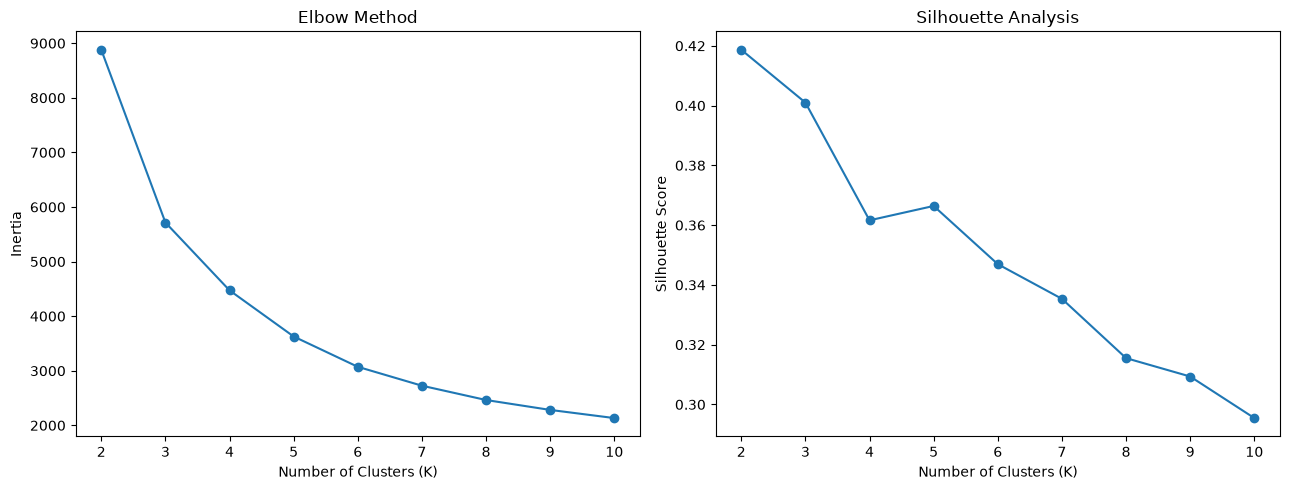

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    list(k_values),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values),
    silhouette_values,
    marker="o"
)
axes[1].set_title("Silhouette Analysis")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "kmeans_model_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare K = 2 and K = 3

In [11]:
from sklearn.cluster import KMeans

candidate_models = {}

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    candidate_models[k] = model

    rfm[f"Cluster_K{k}"] = labels

    print(f"\nCLUSTER DISTRIBUTION FOR K={k}")
    print(rfm[f"Cluster_K{k}"].value_counts().sort_index())


CLUSTER DISTRIBUTION FOR K=2
Cluster_K2
0    3179
1    2699
Name: count, dtype: int64

CLUSTER DISTRIBUTION FOR K=3
Cluster_K3
0    1840
1    1675
2    2363
Name: count, dtype: int64


Profile the customer segments

In [12]:
for k in [2, 3]:

    print(f"\n{'=' * 45}")
    print(f"CUSTOMER PROFILE — K={k}")
    print("=" * 45)

    profile = rfm.groupby(f"Cluster_K{k}").agg(
        Customer_Count=("Customer ID", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median")
    ).round(2)

    profile["Customer_Percentage"] = (
        profile["Customer_Count"] / len(rfm) * 100
    ).round(2)

    display(profile)


CUSTOMER PROFILE — K=2


,Customer_Count,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
Cluster_K2,,,,,,,,
0,3179,317.97,353.0,1.85,1.0,521.74,370.45,54.08
1,2699,63.95,31.0,11.52,7.0,5822.97,2433.28,45.92



CUSTOMER PROFILE — K=3


,Customer_Count,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
Cluster_K3,,,,,,,,
0,1840,472.95,438.0,1.79,1.0,555.30,326.45,31.3
1,1675,57.29,25.0,15.95,11.0,8561.95,3939.24,28.5
2,2363,91.94,61.0,2.94,3.0,851.37,716.54,40.2


Implement Agglomerative Clustering

In [13]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

agglomerative_results = {}

for k in [2, 3]:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(rfm_scaled)

    agglomerative_results[k] = labels

    print(f"\nAGGLOMERATIVE CLUSTERING: K={k}")
    print("-" * 40)

    print("Silhouette:",
          round(silhouette_score(rfm_scaled, labels), 4))

    print("Davies-Bouldin:",
          round(davies_bouldin_score(rfm_scaled, labels), 4))

    print("Calinski-Harabasz:",
          round(calinski_harabasz_score(rfm_scaled, labels), 2))

    print("\nCluster distribution:")
    print(pd.Series(labels).value_counts().sort_index())
    


AGGLOMERATIVE CLUSTERING: K=2
----------------------------------------
Silhouette: 0.3921
Davies-Bouldin: 0.7742
Calinski-Harabasz: 4021.98

Cluster distribution:
0    4692
1    1186
Name: count, dtype: int64

AGGLOMERATIVE CLUSTERING: K=3
----------------------------------------
Silhouette: 0.3501
Davies-Bouldin: 0.9504
Calinski-Harabasz: 5015.26

Cluster distribution:
0    2607
1    1186
2    2085
Name: count, dtype: int64


DBSCAN

Generate the k-distance graph

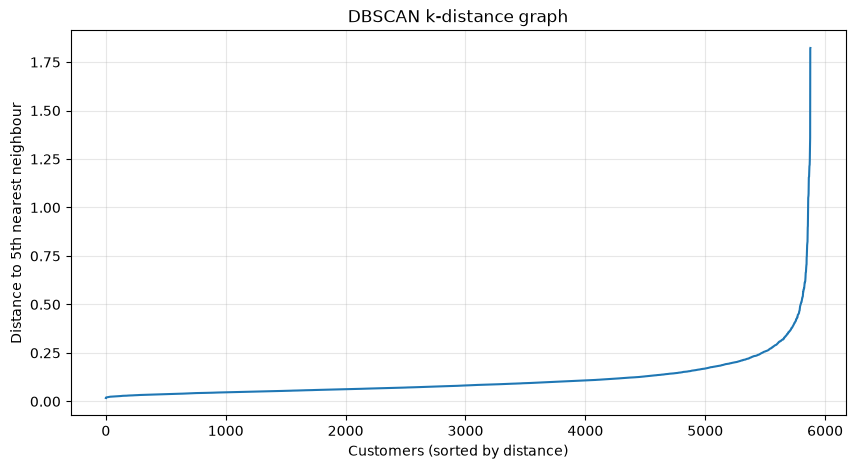

In [29]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Use 5 neighbours as an initial reference
min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(rfm_scaled)

distances, indices = neighbors.kneighbors(rfm_scaled)

# Distance to the fifth nearest neighbour
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Customers (sorted by distance)")
plt.ylabel("Distance to 5th nearest neighbour")
plt.title("DBSCAN k-distance graph")

plt.grid(alpha=0.3)
plt.savefig(
    FIGURE_DIR / "dbscan_k_distance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Test DBSCAN configurations

In [15]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

eps_values = [0.25, 0.30, 0.35, 0.40, 0.45]

dbscan_results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(rfm_scaled)

    # DBSCAN assigns -1 to noise points
    noise_mask = labels == -1
    valid_mask = ~noise_mask

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = noise_mask.sum()
    noise_percentage = noise_count / len(labels) * 100

    # Evaluate only non-noise customers
    if n_clusters >= 2 and valid_mask.sum() > n_clusters:

        valid_labels = labels[valid_mask]
        valid_data = rfm_scaled.loc[valid_mask]

        silhouette = silhouette_score(
            valid_data, valid_labels
        )

        db_index = davies_bouldin_score(
            valid_data, valid_labels
        )

        ch_index = calinski_harabasz_score(
            valid_data, valid_labels
        )

    else:
        silhouette = None
        db_index = None
        ch_index = None

    dbscan_results.append({
        "Eps": eps,
        "Clusters": n_clusters,
        "Noise_Count": noise_count,
        "Noise_Percentage": round(noise_percentage, 2),
        "Silhouette": silhouette,
        "Davies_Bouldin": db_index,
        "Calinski_Harabasz": ch_index
    })

    print(f"\nDBSCAN: eps={eps}, min_samples=5")
    print("Clusters:", n_clusters)
    print("Noise points:", noise_count)
    print("Noise percentage:", round(noise_percentage, 2))

    if silhouette is not None:
        print("Silhouette:", round(silhouette, 4))
        print("Davies-Bouldin:", round(db_index, 4))
        print("Calinski-Harabasz:", round(ch_index, 2))
    else:
        print("Clustering metrics: Not applicable")


DBSCAN: eps=0.25, min_samples=5
Clusters: 9
Noise points: 260
Noise percentage: 4.42
Silhouette: -0.0306
Davies-Bouldin: 1.3938
Calinski-Harabasz: 892.25

DBSCAN: eps=0.3, min_samples=5
Clusters: 6
Noise points: 163
Noise percentage: 2.77
Silhouette: 0.0678
Davies-Bouldin: 1.2747
Calinski-Harabasz: 1066.21

DBSCAN: eps=0.35, min_samples=5
Clusters: 4
Noise points: 111
Noise percentage: 1.89
Silhouette: 0.1412
Davies-Bouldin: 1.6034
Calinski-Harabasz: 1757.68

DBSCAN: eps=0.4, min_samples=5
Clusters: 2
Noise points: 80
Noise percentage: 1.36
Silhouette: 0.3186
Davies-Bouldin: 1.0663
Calinski-Harabasz: 3093.68

DBSCAN: eps=0.45, min_samples=5
Clusters: 2
Noise points: 57
Noise percentage: 0.97
Silhouette: 0.3172
Davies-Bouldin: 1.0668
Calinski-Harabasz: 3077.52


In [16]:
dbscan_comparison = pd.DataFrame(dbscan_results)

display(dbscan_comparison)

,Eps,Clusters,Noise_Count,Noise_Percentage,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,0.25,9,260,4.42,-0.030581,1.393847,892.251932
1,0.30,6,163,2.77,0.067779,1.274659,1066.208307
2,0.35,4,111,1.89,0.141236,1.603380,1757.676112
3,0.40,2,80,1.36,0.318562,1.066320,3093.676949
4,0.45,2,57,0.97,0.317193,1.066832,3077.520538


In [17]:
from sklearn.cluster import DBSCAN

# Train the best DBSCAN candidate
dbscan_final = DBSCAN(
    eps=0.40,
    min_samples=5
)

dbscan_labels = dbscan_final.fit_predict(rfm_scaled)

# Attach labels to customer data
rfm["DBSCAN_Cluster"] = dbscan_labels

print("DBSCAN CLUSTER DISTRIBUTION")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

print("\nCUSTOMER PROFILE")

dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(dbscan_profile)

DBSCAN CLUSTER DISTRIBUTION
DBSCAN_Cluster
-1      80
 0    4188
 1    1610
Name: count, dtype: int64

CUSTOMER PROFILE


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
DBSCAN_Cluster,,,,
-1,80,290.79,43.16,51423.23
0,4188,140.74,7.62,3042.91
1,1610,354.50,1.00,321.28


Consolidated model evaluation

In [18]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

comparison_results = []


def evaluate_clustering(name, labels, data, exclude_noise=False):

    labels = pd.Series(labels, index=data.index)

    # Exclude DBSCAN noise when requested
    if exclude_noise:
        mask = labels != -1
        X = data.loc[mask]
        y = labels.loc[mask]
    else:
        X = data
        y = labels

    n_clusters = y.nunique()

    if n_clusters < 2 or len(y) <= n_clusters:
        return

    comparison_results.append({
        "Model": name,
        "Clusters": n_clusters,
        "Noise_Percentage": (
            round((labels == -1).mean() * 100, 2)
            if exclude_noise else 0
        ),
        "Silhouette": silhouette_score(X, y),
        "Davies_Bouldin": davies_bouldin_score(X, y),
        "Calinski_Harabasz": calinski_harabasz_score(X, y)
    })


# K-Means
for k in [2, 3]:
    model = candidate_models[k]
    labels = model.labels_

    evaluate_clustering(
        f"K-Means K={k}",
        labels,
        rfm_scaled
    )


# Agglomerative
for k in [2, 3]:
    labels = agglomerative_results[k]

    evaluate_clustering(
        f"Agglomerative K={k}",
        labels,
        rfm_scaled
    )


# DBSCAN
evaluate_clustering(
    "DBSCAN eps=0.40",
    dbscan_labels,
    rfm_scaled,
    exclude_noise=True
)


comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.round(4).sort_values(
        "Silhouette",
        ascending=False
    )
)

,Model,Clusters,Noise_Percentage,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,K-Means K=2,2,0.00,0.4187,0.8904,5791.7759
1,K-Means K=3,3,0.00,0.4010,0.8726,6124.8963
2,Agglomerative K=2,2,0.00,0.3921,0.7742,4021.9818
3,Agglomerative K=3,3,0.00,0.3501,0.9504,5015.2593
4,DBSCAN eps=0.40,2,1.36,0.3186,1.0663,3093.6769


Run stability testing

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np

seeds = [10, 20, 30, 40, 50]

stability_results = []

for k in [2, 3]:

    # Reference clustering from our original model
    reference_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    reference_labels = reference_model.fit_predict(
        rfm_scaled
    )

    ari_scores = []

    for seed in seeds:

        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10
        )

        labels = model.fit_predict(rfm_scaled)

        ari = adjusted_rand_score(
            reference_labels,
            labels
        )

        ari_scores.append(ari)

    stability_results.append({
        "K": k,
        "Mean_ARI": np.mean(ari_scores),
        "Std_ARI": np.std(ari_scores),
        "Minimum_ARI": np.min(ari_scores),
        "Maximum_ARI": np.max(ari_scores)
    })

    print(f"\nK-MEANS STABILITY: K={k}")
    print("ARI scores:", np.round(ari_scores, 4))
    print("Mean ARI:", round(np.mean(ari_scores), 4))
    print("Std ARI:", round(np.std(ari_scores), 4))


stability_df = pd.DataFrame(stability_results)

print("\nFINAL STABILITY COMPARISON")
display(stability_df.round(4))


K-MEANS STABILITY: K=2
ARI scores: [1.     1.     0.9993 1.     1.    ]
Mean ARI: 0.9999
Std ARI: 0.0003

K-MEANS STABILITY: K=3
ARI scores: [0.9854 0.9995 0.9881 1.     0.9995]
Mean ARI: 0.9945
Std ARI: 0.0064

FINAL STABILITY COMPARISON


,K,Mean_ARI,Std_ARI,Minimum_ARI,Maximum_ARI
0,2,0.9999,0.0003,0.9993,1.0
1,3,0.9945,0.0064,0.9854,1.0


Train the final K-Means model

In [20]:
from sklearn.cluster import KMeans

final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(rfm_scaled)

# Create final customer segmentation dataset
segmented_customers = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()

segmented_customers["Segment"] = final_labels

print("FINAL CUSTOMER SEGMENTATION")
print("-" * 45)

print("Total customers:", len(segmented_customers))
print("\nSegment distribution:")
print(segmented_customers["Segment"].value_counts().sort_index())

display(segmented_customers.head(10))

FINAL CUSTOMER SEGMENTATION
---------------------------------------------
Total customers: 5878

Segment distribution:
Segment
0    1840
1    1675
2    2363
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,Segment
0,12346,326,12,77556.46,1
1,12347,2,8,4921.53,1
2,12348,75,5,2019.40,2
3,12349,19,4,4428.69,1
4,12350,310,1,334.40,0
5,12351,375,1,300.93,0
6,12352,36,10,2849.84,1
7,12353,204,2,406.76,2
8,12354,232,1,1079.40,2
9,12355,214,2,947.61,2


Create the final customer profiles

In [21]:
final_profile = segmented_customers.groupby("Segment").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

final_profile["Customer_Percentage"] = (
    final_profile["Customer_Count"]
    / len(segmented_customers) * 100
).round(2)

display(final_profile)

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
Segment,,,,,
0,1840,472.95,1.79,555.30,31.3
1,1675,57.29,15.95,8561.95,28.5
2,2363,91.94,2.94,851.37,40.2


Create the final customer profiles

In [22]:
import joblib
from pathlib import Path

ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "segmentation"

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save trained K-Means model
joblib.dump(
    final_kmeans,
    ARTIFACT_DIR / "kmeans_model.pkl"
)

# Save fitted scaler
joblib.dump(
    scaler,
    ARTIFACT_DIR / "rfm_scaler.pkl"
)

# Save customer segmentation results
segmented_customers.to_csv(
    ARTIFACT_DIR / "customer_segments.csv",
    index=False
)

# Save cluster profiles
final_profile.to_csv(
    ARTIFACT_DIR / "segment_profiles.csv"
)

print("Segmentation artifacts saved successfully!")

Segmentation artifacts saved successfully!


final validation

In [24]:
# Apply saved scaler
test_scaled_array = loaded_scaler.transform(test_features)

# Preserve feature names
test_scaled = pd.DataFrame(
    test_scaled_array,
    columns=["Recency", "Frequency", "Monetary"]
)

# Predict using the loaded model
predicted_segments = loaded_model.predict(test_scaled)

original_segments = segmented_customers["Segment"].head(5).values

print("Original assignments:", original_segments)
print("Predicted assignments:", predicted_segments)

print(
    "Predictions match:",
    np.array_equal(original_segments, predicted_segments)
)

Original assignments: [1 1 2 1 0]
Predicted assignments: [1 1 2 1 0]
Predictions match: True


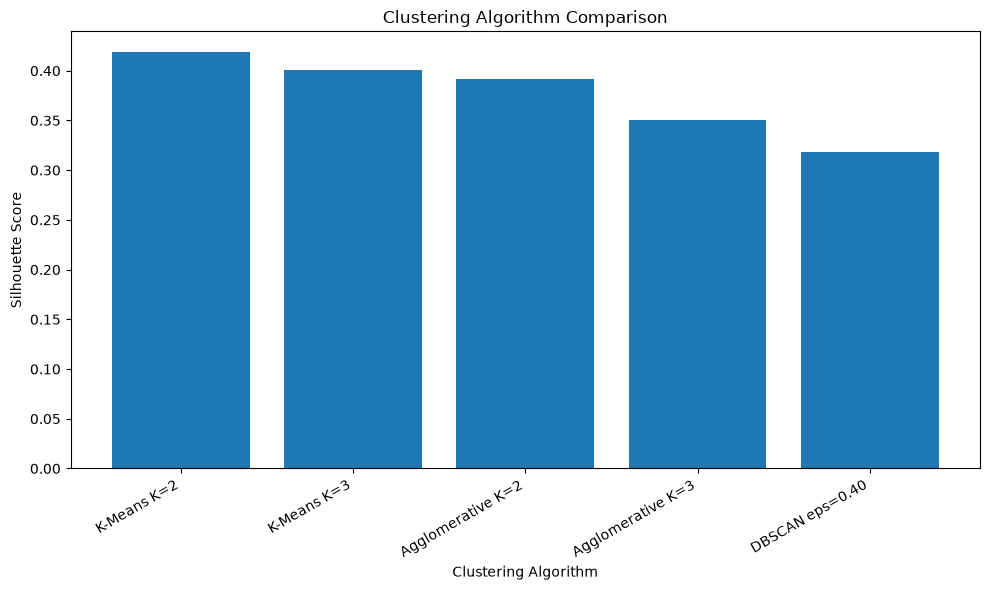

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["Model"],
    comparison_df["Silhouette"]
)

plt.title("Clustering Algorithm Comparison")
plt.xlabel("Clustering Algorithm")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "clustering_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

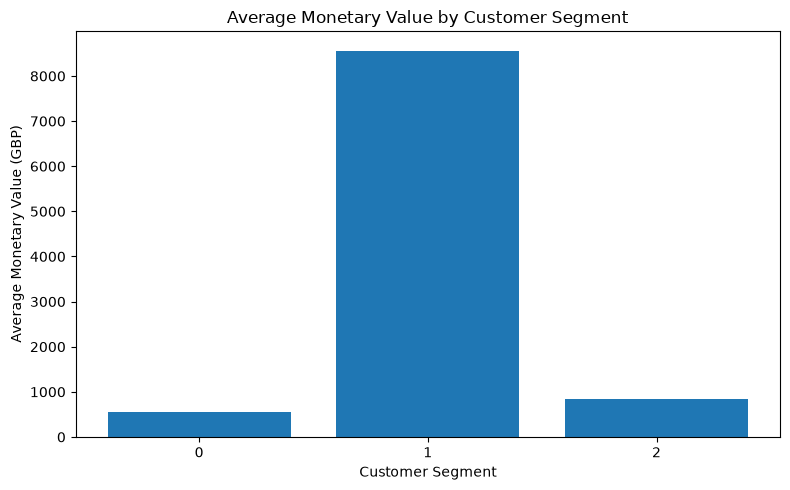

In [31]:
plt.figure(figsize=(8, 5))

plt.bar(
    final_profile.index.astype(str),
    final_profile["Avg_Monetary"]
)

plt.title("Average Monetary Value by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Monetary Value (GBP)")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "customer_segment_profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
for file in FIGURE_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

clustering_comparison.png - 123.15 KB
customer_segment_profiles.png - 76.34 KB
dbscan_k_distance.png - 98.0 KB
kmeans_model_selection.png - 176.3 KB
rfm_distributions_after.png - 218.44 KB
rfm_distributions_before.png - 174.74 KB
